# Step 1 — Getting started and the statistical model

**Unit i** = one lender (`LocationID`) × approval fiscal-year cohort, FY2000–FY2019.
**Y_i** = number of loans in the cohort that were charged off.
**e_i** = loan-years at risk (disbursement → charge-off, payoff or the 2026-09-30 cut-off).

Source, licence and cleaning choices: [`docs/data_sheet.md`](../docs/data_sheet.md).
The cleaning itself lives in `src/sba_mc/data.py`; this section only **verifies** the table we analyse.

## 1.1 Loading and checks

In [1]:
import numpy as np
import pandas as pd

from sba_mc.data import PROCESSED_DIR, load_data

pd.set_option("display.width", 140)
df = load_data()          # cached parquet; run `python scripts/build_data.py` first
print(f"{df.shape[0]:,} units x {df.shape[1]} columns")
df.head()

32,806 units x 20 columns


,lender,fy,Y,e,n_loans,chgoff_amount_total,mean_log_amount,mean_term_months,guar_share,mean_jobs,share_revolver,share_express,share_young,share_collateral,share_franchise,share_sold,sector,business_type,lender_state,lender_name
0,0000020,2002,0,3.756331,1,0.00,11.512925,60.0,0.850,0.0,0.0,0.0,1.00,0.0,0.0,0.0,HealthCare,CORPORATION,AL,The Exchange Bank of Alabama
1,0000020,2003,0,12.588638,2,0.00,11.831214,120.0,0.850,0.0,0.0,0.0,0.50,0.0,0.0,0.0,Manufacturing,INDIVIDUAL,AL,The Exchange Bank of Alabama
2,0000020,2004,0,12.410678,2,0.00,12.052164,84.0,0.625,23.5,0.5,0.5,0.00,0.0,0.0,0.0,Retail,CORPORATION,AL,The Exchange Bank of Alabama
3,0000020,2005,2,14.652977,4,269031.65,11.542371,57.0,0.500,16.0,0.5,1.0,0.25,0.5,0.0,0.0,Information,CORPORATION,AL,The Exchange Bank of Alabama
4,0000020,2007,0,3.926078,2,0.00,11.348673,81.0,0.500,6.0,0.5,1.0,0.50,0.0,0.0,0.0,Construction,CORPORATION,AL,The Exchange Bank of Alabama


### Column types and roles

In [2]:
roles = {
    "lender": "group (steps 4-5) / key", "fy": "key + categorical covariate (20 levels)",
    "Y": "count Y_i", "e": "exposure e_i (loan-years)", "n_loans": "continuous covariate",
    "chgoff_amount_total": "amounts (step 11, aggregated)", "sector": "categorical covariate",
    "business_type": "categorical covariate", "lender_state": "categorical covariate",
    "lender_name": "label only",
}
types = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "role": [roles.get(c, "continuous covariate (cohort mean / share)") for c in df.columns],
    "n_unique": df.nunique(),
})
types

,dtype,role,n_unique
lender,object,group (steps 4-5) / key,4940
fy,int64,key + categorical covariate (20 levels),20
Y,int64,count Y_i,297
e,float64,exposure e_i (loan-years),18379
n_loans,int64,continuous covariate,703
chgoff_amount_total,float64,"amounts (step 11, aggregated)",12099
mean_log_amount,float64,continuous covariate (cohort mean / share),23045
mean_term_months,float64,continuous covariate (cohort mean / share),9213
guar_share,float64,continuous covariate (cohort mean / share),4745
mean_jobs,float64,continuous covariate (cohort mean / share),6018


### Missing values

No NaN is left. Unknown categories are coded as explicit levels instead, so we count those too.

In [3]:
na = df.isna().sum()
print("NaN cells in the whole table:", int(na.sum()))

placeholders = pd.Series({
    'sector == "Unknown" (NAICS missing, mostly early loans)': (df["sector"] == "Unknown").sum(),
    'business_type == "UNKNOWN"': (df["business_type"] == "UNKNOWN").sum(),
    'lender_state == "UNK"': (df["lender_state"] == "UNK").sum(),
}, name="units")
placeholders.to_frame()

NaN cells in the whole table: 0


,units
"sector == ""Unknown"" (NAICS missing, mostly early loans)",931
"business_type == ""UNKNOWN""",10
"lender_state == ""UNK""",3


### Duplicates

The key is `(lender, fy)`: each cohort must appear once.

In [4]:
n_dup = df.duplicated(["lender", "fy"]).sum()
print("duplicated (lender, fy) keys:", n_dup)
assert n_dup == 0

duplicated (lender, fy) keys: 0


### Exposure units

`e` is in **loan-years** (days / 365.25, summed over the loans of the cohort).
Check: strictly positive, and the time at risk per loan (`e / n_loans`) cannot exceed the
~27 years between the start of FY2000 (1999-10-01) and the cut-off (2026-09-30).

In [5]:
per_loan = df["e"] / df["n_loans"]
assert (df["e"] > 0).all()
assert per_loan.max() <= 27.1
pd.DataFrame({"e (loan-years)": df["e"].describe(),
              "e / n_loans (years per loan)": per_loan.describe()}).round(2)

,e (loan-years),e / n_loans (years per loan)
count,32806.00,32806.00
mean,179.74,5.70
std,1348.76,2.55
min,0.07,0.07
25%,7.17,4.25
50%,17.34,5.39
75%,54.41,6.75
max,49955.85,25.49


### Consistency checks

In [6]:
checks = pd.Series({
    "Y < 0": (df["Y"] < 0).sum(),
    "Y > n_loans": (df["Y"] > df["n_loans"]).sum(),
    "Y = 0 but charge-off amount != 0": ((df["Y"] == 0) & (df["chgoff_amount_total"] != 0)).sum(),
    "Y > 0 but charge-off amount <= 0": ((df["Y"] > 0) & (df["chgoff_amount_total"] <= 0)).sum(),
    "guar_share outside [0, 1]": (~df["guar_share"].between(0, 1)).sum(),
    "share_* outside [0, 1]": (~df.filter(like="share_").stack().between(0, 1)).sum(),
    "mean_term_months == 0": (df["mean_term_months"] == 0).sum(),
}, name="violations (units)")
assert checks[["Y < 0", "Y > n_loans", "Y = 0 but charge-off amount != 0"]].sum() == 0
checks.to_frame()

,violations (units)
Y < 0,0
Y > n_loans,0
Y = 0 but charge-off amount != 0,0
Y > 0 but charge-off amount <= 0,1
"guar_share outside [0, 1]",0
"share_* outside [0, 1]",0
mean_term_months == 0,5


In [7]:
# the two non-zero lines above, in detail
df.loc[(df["Y"] > 0) & (df["chgoff_amount_total"] <= 0), ["lender", "fy", "Y", "n_loans", "chgoff_amount_total"]]

,lender,fy,Y,n_loans,chgoff_amount_total
19669,0076551,2016,1,9,0.0


### What the cleaning already removed

In [8]:
log = pd.read_csv(PROCESSED_DIR / "cleaning_log_2000s_2010s_2020s.csv")
log

,step,rows
0,raw rows,1639728
1,drop exact duplicates,-2383
2,drop CANCLD / COMMIT,-221847
3,drop missing lender or FY,-14
4,drop non-positive / undefined time at risk,-5278
5,final loans,1410206


In [9]:
print(f"Analysis table: {df['n_loans'].sum():,} loans (FY2000-2019) -> {len(df):,} units, "
      f"{df['lender'].nunique():,} lenders, {df['Y'].sum():,} charge-offs, {df['e'].sum()/1e6:.2f} M loan-years")

Analysis table: 1,081,254 loans (FY2000-2019) -> 32,806 units, 4,940 lenders, 178,803 charge-offs, 5.90 M loan-years


### Findings

* **No missing values, no duplicate keys, every exposure strictly positive** and consistent with the
  observation window. `Y` never exceeds the number of loans, and units with `Y = 0` carry no loss.
* Unknown categories are explicit levels: 931 units with `sector = "Unknown"`, 10 with
  `business_type = "UNKNOWN"`, 3 with `lender_state = "UNK"`. They are kept as their own level.
* **1 unit** (lender 0076551, FY2016) has one charge-off recorded with a gross amount of $0.
  It stays in the count models; step 11 drops amounts ≤ 0 (18 loans, see data sheet).
* **1,139 loans (0.1 %) have `TermInMonths = 0`**, which is impossible for a 7(a) loan. This pulls
  `mean_term_months` down in the cohorts that contain them (5 units average exactly 0).
  Small enough to leave as is; to be treated as missing if `mean_term_months` matters in the GLM.

## 1.2 Descriptive statistics

All rates are **raw rates** `ΣY / Σe`, expressed **per 1,000 loan-years**. They are exposure-weighted, so
large lenders weigh more than small ones. The 95 % intervals are exact Poisson (Garwood) intervals:
they assume the Poisson model, so with the overdispersion seen in step 2 they are **too narrow**.
They are only there to show which differences are far beyond sampling noise.

In [10]:
import matplotlib.pyplot as plt
from scipy import stats

FIG_DIR = PROCESSED_DIR.parents[1] / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# chart style: one blue series, muted reference lines, recessive grid
BLUE, INK, INK2, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "axes.facecolor": "#fcfcfb", "figure.facecolor": "white",
})

LAM = df["Y"].sum() / df["e"].sum()      # pooled rate
PER = 1000                               # report rates per 1,000 loan-years
print(f"Pooled raw rate: {PER * LAM:.1f} charge-offs per 1,000 loan-years")


def rate_table(data, by):
    """Units, Y, e and raw rate (per 1,000 loan-years) with exact Poisson 95% CI, per level of `by`."""
    t = data.groupby(by, observed=True).agg(units=("Y", "size"), Y=("Y", "sum"), e=("e", "sum"))
    t["rate"] = PER * t["Y"] / t["e"]
    t["ci_low"] = PER * stats.chi2.ppf(0.025, 2 * t["Y"]) / 2 / t["e"]
    t["ci_high"] = PER * stats.chi2.ppf(0.975, 2 * t["Y"] + 2) / 2 / t["e"]
    t["ci_low"] = t["ci_low"].fillna(0.0)          # Y = 0 -> lower bound 0
    return t.round({"e": 0, "rate": 1, "ci_low": 1, "ci_high": 1})


def dot_plot(ax, t, title, horizontal=False):
    """Rate per level with its CI, against the pooled rate."""
    pos = np.arange(len(t))
    err = [t["rate"] - t["ci_low"], t["ci_high"] - t["rate"]]
    if horizontal:
        ax.errorbar(t["rate"], pos, xerr=err, fmt="o", ms=5, color=BLUE, ecolor=BLUE, elinewidth=1.5, capsize=0)
        ax.axvline(PER * LAM, color=MUTED, lw=1, ls="--")
        ax.set_yticks(pos, t.index.astype(str)); ax.grid(axis="y", visible=False)
        ax.set_xlabel("charge-offs per 1,000 loan-years"); ax.set_xlim(left=0)
    else:
        ax.errorbar(pos, t["rate"], yerr=err, fmt="o", ms=5, color=BLUE, ecolor=BLUE, elinewidth=1.5, capsize=0)
        ax.axhline(PER * LAM, color=MUTED, lw=1, ls="--")
        ax.set_xticks(pos, t.index.astype(str)); ax.grid(axis="x", visible=False)
        ax.set_ylabel("per 1,000 loan-years"); ax.set_ylim(bottom=0)
    ax.set_title(title, loc="left")

Pooled raw rate: 30.3 charge-offs per 1,000 loan-years


### Distribution of Y (charge-offs per unit) and e (loan-years per unit)

In [11]:
Y, e = df["Y"], df["e"]
summary = pd.DataFrame({
    "Y": Y.describe(percentiles=[.5, .75, .9, .95, .99]),
    "e": e.describe(percentiles=[.5, .75, .9, .95, .99]),
    "n_loans": df["n_loans"].describe(percentiles=[.5, .75, .9, .95, .99]),
}).round(1)
summary.loc["share of zeros"] = [(Y == 0).mean().round(3), np.nan, np.nan]
summary.loc["variance"] = [Y.var().round(0), e.var().round(0), df["n_loans"].var().round(0)]
summary

,Y,e,n_loans
count,32806.00,32806.0,32806.0
mean,5.50,179.7,33.0
std,77.40,1348.8,262.4
min,0.00,0.1,1.0
50%,0.00,17.3,3.0
75%,1.00,54.4,10.0
90%,3.00,179.1,32.0
95%,8.00,424.4,75.0
99%,64.00,2864.2,526.0
max,4983.00,49955.9,10998.0


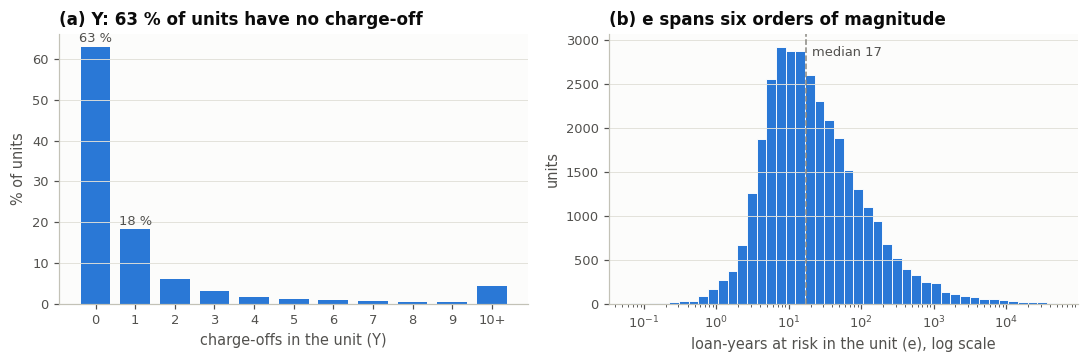

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))

# (a) Y: share of units for 0..9 and 10+
k = np.minimum(Y, 10)
share = k.value_counts(normalize=True).sort_index()
a1.bar(share.index, 100 * share.values, width=0.75, color=BLUE)
a1.set_xticks(range(11), [str(i) for i in range(10)] + ["10+"])
a1.set_xlabel("charge-offs in the unit (Y)"); a1.set_ylabel("% of units"); a1.grid(axis="x", visible=False)
a1.set_title("(a) Y: 63 % of units have no charge-off", loc="left")
for x, v in zip(share.index[:2], 100 * share.values[:2]):
    a1.annotate(f"{v:.0f} %", (x, v), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8.5, color=INK2)

# (b) e on a log scale
bins = np.logspace(np.log10(e.min()), np.log10(e.max()), 45)
a2.hist(e, bins=bins, color=BLUE, edgecolor="white", linewidth=0.6)
a2.set_xscale("log"); a2.set_xlabel("loan-years at risk in the unit (e), log scale"); a2.set_ylabel("units")
a2.axvline(e.median(), color=MUTED, lw=1, ls="--")
a2.annotate(f"median {e.median():.0f}", (e.median(), a2.get_ylim()[1] * 0.92), xytext=(4, 0),
            textcoords="offset points", fontsize=8.5, color=INK2)
a2.set_title("(b) e spans six orders of magnitude", loc="left"); a2.grid(axis="x", visible=False)

fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_1_distribution_Y_e.png"); plt.show()

### Is Y proportional to e?

The base model says `E[Y] = λ·e`: on a log-log plot the points should scatter around a line of slope 1.
Units with `Y = 0` cannot be drawn on a log axis; they are counted in the title.

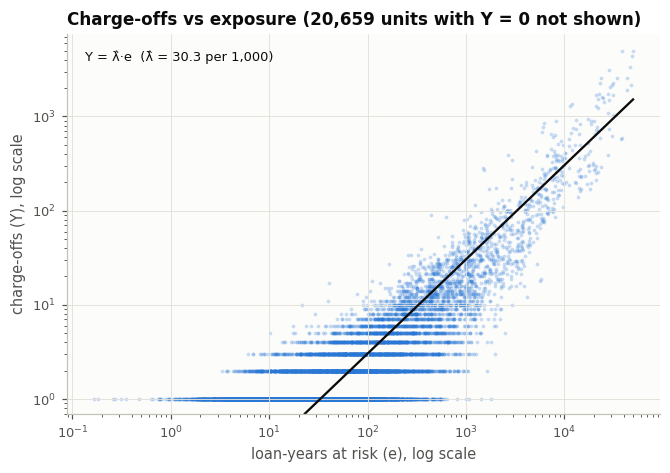

In [13]:
pos_ = df[df["Y"] > 0]
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.scatter(pos_["e"], pos_["Y"], s=6, alpha=0.25, color=BLUE, linewidths=0)
grid = np.logspace(np.log10(0.7 / LAM), np.log10(e.max()), 50)     # line drawn where λe >= 0.7
ax.plot(grid, LAM * grid, color=INK, lw=1.5)
ax.annotate(f"Y = λ̂·e  (λ̂ = {PER*LAM:.1f} per 1,000)", (0.03, 0.93), xycoords="axes fraction",
            fontsize=8.5, color=INK)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(0.7, Y.max() * 1.5)
ax.set_xlabel("loan-years at risk (e), log scale"); ax.set_ylabel("charge-offs (Y), log scale")
ax.set_title(f"Charge-offs vs exposure ({(df['Y']==0).sum():,} units with Y = 0 not shown)", loc="left")

fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_2_Y_vs_e.png"); plt.show()

The scatter alone is misleading: dropping the zeros keeps the small units that were unlucky, which
flattens the cloud. Two checks that use **all** units:

* the raw rate by decile of e: flat if Y is proportional to e;
* the slope of log e in a Poisson regression `log E[Y] = a + b·log e`: equal to 1 if proportional.

In [14]:
import statsmodels.api as sm

t_e = rate_table(df.assign(e_decile=pd.qcut(df["e"], 10)), "e_decile")
t_e["share Y = 0"] = df.groupby(pd.qcut(df["e"], 10), observed=True)["Y"].apply(lambda y: (y == 0).mean()).round(2).values

glm_e = sm.GLM(df["Y"], sm.add_constant(np.log(df["e"])), family=sm.families.Poisson()).fit()
print(f"Poisson regression slope of log e: b = {glm_e.params.iloc[1]:.3f} (1 = proportional)")

top10 = df.groupby("lender")[["Y", "e"]].sum().nlargest(10, "e").sum() / df[["Y", "e"]].sum()
print(f"10 largest lenders: {top10['e']:.0%} of exposure, {top10['Y']:.0%} of charge-offs")
t_e

Poisson regression slope of log e: b = 1.187 (1 = proportional)
10 largest lenders: 40% of exposure, 50% of charge-offs


,units,Y,e,rate,ci_low,ci_high,share Y = 0
e_decile,,,,,,,
"(0.0647, 3.914]",3281,544,8087.0,67.3,61.7,73.2,0.84
"(3.914, 6.001]",3297,504,16311.0,30.9,28.3,33.7,0.85
"(6.001, 8.645]",3264,603,23709.0,25.4,23.4,27.5,0.83
"(8.645, 12.249]",3288,665,33870.0,19.6,18.2,21.2,0.83
"(12.249, 17.342]",3274,915,47933.0,19.1,17.9,20.4,0.78
"(17.342, 26.067]",3280,1325,70127.0,18.9,17.9,19.9,0.71
"(26.067, 41.652]",3280,1965,108302.0,18.1,17.4,19.0,0.61
"(41.652, 74.554]",3281,3276,182467.0,18.0,17.3,18.6,0.47
"(74.554, 179.065]",3280,6391,379947.0,16.8,16.4,17.2,0.31


### Raw rate by level of each categorical covariate

#### Approval fiscal year (`fy`)

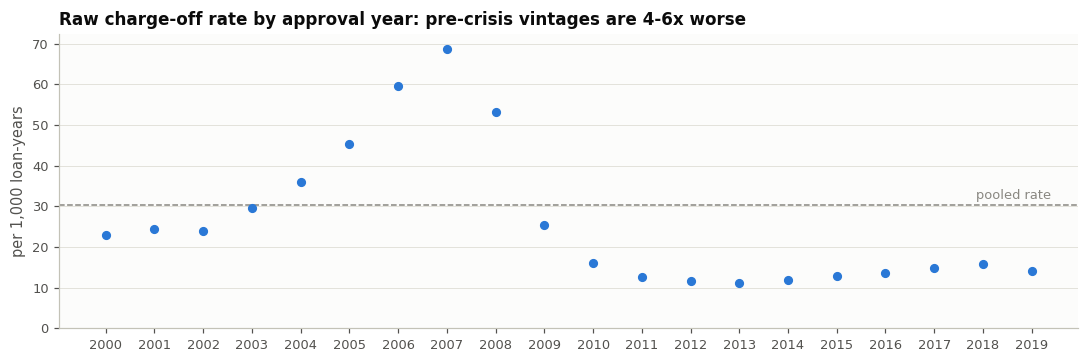

fy,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
units,1787.0,1784.0,1874.0,1858.0,1852.0,1799.0,1534.0,1547.0,1488.0,1577.0,1706.0,1725.0,1647.0,1570.0,1553.0,1553.0,1549.0,1524.0,1457.0,1422.0
Y,5555.0,5445.0,6073.0,9095.0,13162.0,20675.0,27788.0,32407.0,18657.0,5392.0,3668.0,3147.0,2444.0,2422.0,2942.0,3812.0,4111.0,4398.0,4403.0,3207.0
e,241471.0,222056.0,253576.0,308624.0,364878.0,456366.0,466870.0,471864.0,350710.0,212080.0,227193.0,251638.0,209392.0,218876.0,244228.0,294716.0,300354.0,297205.0,278143.0,226167.0
rate,23.0,24.5,23.9,29.5,36.1,45.3,59.5,68.7,53.2,25.4,16.1,12.5,11.7,11.1,12.0,12.9,13.7,14.8,15.8,14.2
ci_low,22.4,23.9,23.4,28.9,35.5,44.7,58.8,67.9,52.4,24.8,15.6,12.1,11.2,10.6,11.6,12.5,13.3,14.4,15.4,13.7
ci_high,23.6,25.2,24.6,30.1,36.7,45.9,60.2,69.4,54.0,26.1,16.7,13.0,12.1,11.5,12.5,13.4,14.1,15.2,16.3,14.7


In [15]:
t_fy = rate_table(df, "fy")
fig, ax = plt.subplots(figsize=(10, 3.4))
dot_plot(ax, t_fy, "Raw charge-off rate by approval year: pre-crisis vintages are 4-6x worse")
ax.annotate("pooled rate", (len(t_fy) - 0.6, PER * LAM), xytext=(0, 4), textcoords="offset points",
            ha="right", fontsize=8.5, color=MUTED)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_3_rate_by_fy.png"); plt.show()
t_fy.T

#### Sector (dominant 2-digit NAICS of the cohort)

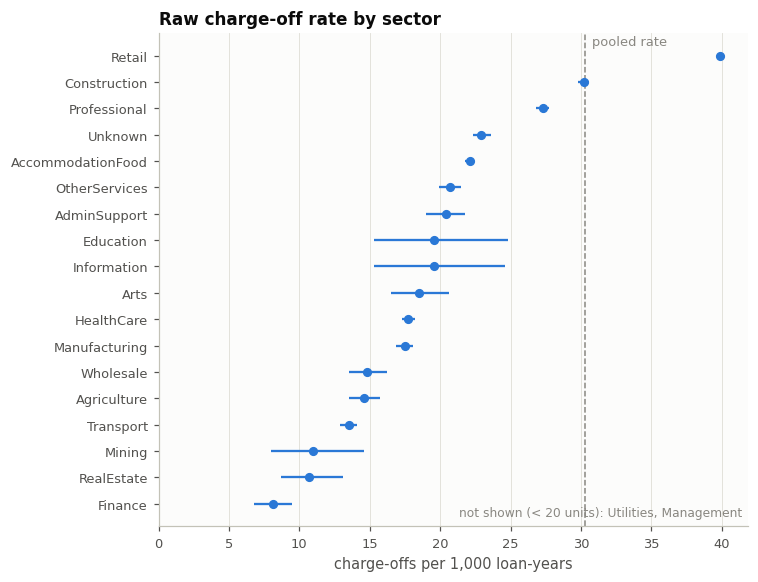

,units,Y,e,rate,ci_low,ci_high
sector,,,,,,
Finance,286,144,17833.0,8.1,6.8,9.5
Utilities,17,2,203.0,9.9,1.2,35.6
RealEstate,298,96,8940.0,10.7,8.7,13.1
Mining,142,47,4291.0,11.0,8.0,14.6
Transport,537,1924,142647.0,13.5,12.9,14.1
Agriculture,743,720,49411.0,14.6,13.5,15.7
Wholesale,829,494,33384.0,14.8,13.5,16.2
Manufacturing,3242,3344,191600.0,17.5,16.9,18.1
HealthCare,2581,5202,293187.0,17.7,17.3,18.2


In [16]:
t_sec = rate_table(df, "sector").sort_values("rate")
small = t_sec.index[t_sec["units"] < 20]
fig, ax = plt.subplots(figsize=(7, 5.4))
dot_plot(ax, t_sec.drop(small), "Raw charge-off rate by sector", horizontal=True)
ax.annotate("pooled rate", (PER * LAM, len(t_sec) - len(small) - 0.6), xytext=(4, 0), textcoords="offset points",
            fontsize=8.5, color=MUTED)
ax.text(0.99, 0.02, f"not shown (< 20 units): {', '.join(small)}", transform=ax.transAxes, ha="right",
        fontsize=8, color=MUTED)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_4_rate_by_sector.png"); plt.show()
t_sec

#### Business type

In [17]:
rate_table(df, "business_type")

,units,Y,e,rate,ci_low,ci_high
business_type,,,,,,
CORPORATION,28447,173030,5712292.0,30.3,30.1,30.4
INDIVIDUAL,3863,5667,179043.0,31.7,30.8,32.5
PARTNERSHIP,486,99,5001.0,19.8,16.1,24.1
UNKNOWN,10,7,71.0,98.6,39.6,203.1


#### Lender state

61 levels. Besides the 50 states, DC and the territories (PR, GU, VI), a few lenders are recorded with a
foreign location (Ontario, Istanbul, Tel Aviv, Gujarat, Maharashtra, Java) or none (`UNK`): 13 units in all.
Showing the 10 lowest and 10 highest among states with at least 1,000 loan-years.

In [18]:
t_st = rate_table(df, "lender_state").sort_values("rate")
print(f"{len(t_st)} levels; {(t_st['e'] < 1000).sum()} have fewer than 1,000 loan-years")
big = t_st[t_st["e"] >= 1000]
pd.concat([big.head(10), big.tail(10)])

61 levels; 8 have fewer than 1,000 loan-years


,units,Y,e,rate,ci_low,ci_high
lender_state,,,,,,
GU,58,27,2516.0,10.7,7.1,15.6
WY,234,50,3975.0,12.6,9.3,16.6
VT,229,151,11638.0,13.0,11.0,15.2
NM,278,169,12952.0,13.0,11.2,15.2
ID,165,113,8612.0,13.1,10.8,15.8
MA,1113,1654,118841.0,13.9,13.3,14.6
ND,642,340,23770.0,14.3,12.8,15.9
NH,234,146,10064.0,14.5,12.2,17.1
GA,751,710,48752.0,14.6,13.5,15.7


### Raw rate by class of each continuous covariate

Means and amounts are cut into quintiles (fewer classes when many ties). Shares are cut into
`0`, four intermediate classes and `1`, because many small cohorts sit exactly at 0 or 1.

In [19]:
cont = ["mean_log_amount", "mean_term_months", "guar_share", "mean_jobs", "n_loans"]
shares = [c for c in df.columns if c.startswith("share_")]
share_bins = [-0.001, 0, 0.25, 0.5, 0.75, 0.999, 1]
share_labels = ["0", "(0, .25]", "(.25, .5]", "(.5, .75]", "(.75, 1)", "1"]

binned = {}
for c in cont:
    binned[c] = rate_table(df.assign(cls=pd.qcut(df[c], 5, duplicates="drop")), "cls")
for c in shares:
    binned[c] = rate_table(df.assign(cls=pd.cut(df[c], share_bins, labels=share_labels)), "cls")

spread = pd.DataFrame({c: {"classes": len(t), "lowest rate": t["rate"].min(), "highest rate": t["rate"].max(),
                           "ratio high / low": round(t["rate"].max() / t["rate"].min(), 1)}
                       for c, t in binned.items()}).T.sort_values("ratio high / low", ascending=False)
spread

,classes,lowest rate,highest rate,ratio high / low
mean_term_months,5.0,14.9,62.0,4.2
share_collateral,6.0,11.5,42.0,3.7
mean_log_amount,5.0,17.2,44.1,2.6
share_express,6.0,17.8,44.7,2.5
mean_jobs,4.0,17.7,43.4,2.5
share_revolver,6.0,20.6,51.1,2.5
guar_share,5.0,19.6,38.5,2.0
share_young,6.0,16.6,32.8,2.0
share_sold,6.0,19.8,37.8,1.9
n_loans,4.0,18.5,31.4,1.7


In [20]:
# the full tables
for c, t in binned.items():
    print(f"--- {c}"); display(t)

--- mean_log_amount


,units,Y,e,rate,ci_low,ci_high
cls,,,,,,
"(7.8999999999999995, 11.184]",6584,105802,2398598.0,44.1,43.8,44.4
"(11.184, 11.645]",6539,26255,1160718.0,22.6,22.3,22.9
"(11.645, 12.075]",6561,17186,805135.0,21.3,21.0,21.7
"(12.075, 12.722]",6561,16937,797295.0,21.2,20.9,21.6
"(12.722, 15.425]",6561,12623,734661.0,17.2,16.9,17.5


--- mean_term_months


,units,Y,e,rate,ci_low,ci_high
cls,,,,,,
"(-0.001, 72.0]",6765,56908,917867.0,62.0,61.5,62.5
"(72.0, 89.0]",6371,42711,1182744.0,36.1,35.8,36.5
"(89.0, 117.0]",6565,44849,1831471.0,24.5,24.3,24.7
"(117.0, 150.0]",6548,20498,1038658.0,19.7,19.5,20.0
"(150.0, 360.0]",6557,13837,925667.0,14.9,14.7,15.2


--- guar_share


,units,Y,e,rate,ci_low,ci_high
cls,,,,,,
"(0.339, 0.625]",6979,100541,2799522.0,35.9,35.7,36.1
"(0.625, 0.75]",10943,31367,1602499.0,19.6,19.4,19.8
"(0.75, 0.775]",2114,12604,578368.0,21.8,21.4,22.2
"(0.775, 0.85]",11174,31570,819767.0,38.5,38.1,38.9
"(0.85, 0.9]",1596,2721,96252.0,28.3,27.2,29.4


... (12 outputs left out)

--- share_franchise


,units,Y,e,rate,ci_low,ci_high
cls,,,,,,
0,22093,10365,558473.0,18.6,18.2,18.9
"(0, .25]",7278,161435,5062830.0,31.9,31.7,32.0
"(.25, .5]",2113,5353,210028.0,25.5,24.8,26.2
"(.5, .75]",235,1240,49884.0,24.9,23.5,26.3
"(.75, 1)",38,225,8104.0,27.8,24.3,31.6
1,1049,185,7088.0,26.1,22.5,30.1


--- share_sold


,units,Y,e,rate,ci_low,ci_high
cls,,,,,,
0,24232,42523,1795251.0,23.7,23.5,23.9
"(0, .25]",1823,78140,2064626.0,37.8,37.6,38.1
"(.25, .5]",1715,10262,517839.0,19.8,19.4,20.2
"(.5, .75]",1296,10713,448599.0,23.9,23.4,24.3
"(.75, 1)",1375,34698,954264.0,36.4,36.0,36.7
1,2365,2467,115827.0,21.3,20.5,22.2


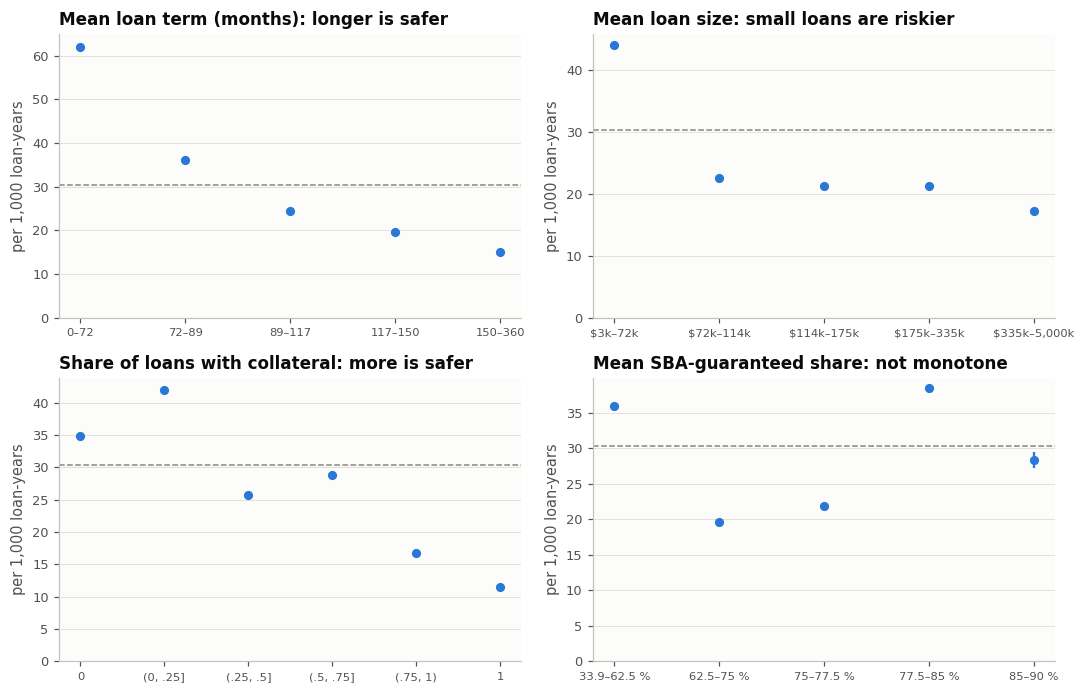

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4))
panels = [("mean_term_months", "Mean loan term (months): longer is safer"),
          ("mean_log_amount", "Mean loan size: small loans are riskier"),
          ("share_collateral", "Share of loans with collateral: more is safer"),
          ("guar_share", "Mean SBA-guaranteed share: not monotone")]
pct = lambda x: f"{100 * x:.1f}".rstrip("0").rstrip(".")
fmt = {  # readable class labels
    "mean_term_months": lambda iv: f"{max(iv.left, 0):.0f}–{iv.right:.0f}",
    "mean_log_amount": lambda iv: f"${np.exp(iv.left)/1e3:,.0f}k–{np.exp(iv.right)/1e3:,.0f}k",
    "guar_share": lambda iv: f"{pct(iv.left)}–{pct(iv.right)} %",
}
for ax, (c, title) in zip(axes.flat, panels):
    t = binned[c].copy()
    if c in fmt:
        t.index = [fmt[c](iv) for iv in t.index]
    dot_plot(ax, t, title)
    ax.tick_params(axis="x", labelsize=7.5)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_5_rate_by_continuous.png"); plt.show()

### Findings

**Distributions**
* **Y is a typical small count with a huge tail.** 63 % of units have no charge-off, 18 % have one;
  the median is 0 and the 90th percentile 3, but the maximum is 4,983.
* **e varies by six orders of magnitude** (0.07 to ~50,000 loan-years, median 17). Most units are small
  cohorts of a few loans; the 10 largest lenders hold 40 % of all exposure and 50 % of all charge-offs.
  The raw variance of Y (≈ 6,000 vs a mean of 5.5) mostly reflects these exposure differences, not yet
  overdispersion: that question needs the rate model of step 2.
* **Proportionality to e holds in the middle, not at the ends.** The raw rate is flat (17–20 per 1,000)
  across exposure deciles 3 to 9, but it is 67 in the smallest decile and 32 in the largest; the Poisson
  regression slope of log e is 1.19 instead of 1.
  * *Small e:* exposure stops at the charge-off, so a cohort whose loans fail early has little exposure
    *because* of its charge-offs. Under the survival reading of the model this selection is expected
    (the likelihood is still right), but it means e is not fixed in advance.
  * *Large e:* the largest cohorts belong to the biggest lenders, which are riskier (next point).

**Raw rates** (pooled: **30.3 per 1,000 loan-years**)
* **Vintage is the dominant factor**: 11.1 (FY2013) to 68.7 (FY2007). Loans approved in 2005–2008 met
  the 2008–09 recession early in their life. Rates fall back to 12–16 for FY2010–2019, part of which is
  the shorter observation window of recent cohorts.
* **Loan terms point the same way**: short loans (≤ 6 years) charge off at 62 vs 15 for terms > 12.5 years
  (mostly real-estate backed); small loans (< $72k) at 44 vs 17 above $335k; cohorts where all loans are
  collateralised at 11.5 vs 34.8 where none are. These covariates overlap (small, short, unsecured loans
  are typically SBA Express), so the GLM of step 9 is needed to separate them.
* **Sector**: Retail (39.9) and Construction (30.2) are highest, Finance and Real Estate (8–11) lowest.
* **Business type** matters little (30–32 for corporations and individuals). `UNKNOWN` has 10 units only.
* **Guaranteed share is not monotone**: low guarantees (≤ 62.5 %, i.e. Express loans at 50 %) and
  high ones (77.5–85 %, small loans) are both riskier than 75 %.
* **Large-lender cohorts are riskier** (31 vs 19–22 for cohorts of ≤ 14 loans). Since raw rates are
  exposure-weighted, the pooled 30.3 is pulled up by them: the 10 largest lenders carry 40 % of the
  exposure and 50 % of the charge-offs.

**Consequences for the model**
* Homogeneity (one λ for everyone) is clearly false: rates differ by a factor 6 across years and 5 across
  sectors, far beyond the Poisson intervals. Expect strong overdispersion in step 2.
* Tiny levels (foreign / unknown lender states, `business_type = UNKNOWN`, sectors with < 20 units)
  should be pooled into an "Other" level before fitting GLMs.

## 1.3 The base model and its assumptions

**Notation.** Unit $i = 1,\dots,n$ ($n = 32{,}806$) is one lender × approval-FY cohort.
$Y_i$ = number of charge-offs, $e_i$ = loan-years at risk, $x_i$ = covariates, $g(i)$ = lender,
$X_{ij}$ = gross amount of the $j$-th charge-off of unit $i$ (step 11).

**Base model.**
$$Y_i \overset{\text{ind.}}{\sim} \text{Poisson}(\lambda\, e_i), \qquad \lambda > 0 \text{ = charge-offs per loan-year.}$$

**Why the exposure is time at risk: the survival reading.** Suppose every loan $k$ has a time to
charge-off $T_k \sim \text{Exp}(\lambda)$ (constant hazard $\lambda$), observed until a censoring time
$C_k$ (payoff or the 2026-09-30 cut-off). We see $t_k = \min(T_k, C_k)$ and $\delta_k = 1\{T_k \le C_k\}$,
and the likelihood of loan $k$ is $\lambda^{\delta_k} e^{-\lambda t_k}$. Multiplying over the loans of
unit $i$, with $Y_i = \sum_k \delta_k$ and $e_i = \sum_k t_k$:
$$\prod_{k \in i} \lambda^{\delta_k} e^{-\lambda t_k} = \lambda^{Y_i} e^{-\lambda e_i}
\;\propto\; \frac{(\lambda e_i)^{Y_i} e^{-\lambda e_i}}{Y_i!}.$$
The two differ by $e_i^{Y_i}/Y_i!$, which does not involve $\lambda$: **the censored-exponential
likelihood and the Poisson($\lambda e_i$) likelihood give the same MLE, the same likelihood-ratio tests
and the same posterior.** The Poisson GLM with offset $\log e_i$ (step 9) is therefore a survival model
with a hazard that depends on covariates. One caveat: $e_i$ is not fixed in advance, it ends at the
charge-off (section 1.2: the smallest exposures have the highest rates).

### Assumptions, how plausible they are here, and how each will be tested

| # | Assumption | What it means for SBA loans | Evidence so far | Verdict | Tested in |
|---|---|---|---|---|---|
| A1 | **Independence** of the $Y_i$ | One cohort's charge-offs tell nothing about another's | All cohorts of a vintage meet the same economy: FY2005–08 rates are 45–69 vs 11–16 for FY2011–19 | **Doubtful** | Step 9: residuals by `fy`, robust SE clustered by year. Step 11: cohort-year frailty model vs independent model |
| A2 | **Homogeneity**: one λ for every unit | Every lender, sector, year has the same risk per loan-year | Rates range ×6 across years, ×5 across sectors, ×4 across loan terms, far outside the Poisson intervals | **False** | Step 2: NB vs Poisson. Step 4: LRT for overdispersion, lender-vs-overall tests. Step 9: GLM with covariates, LR tests on blocks |
| A3 | **Proportionality to exposure** (constant hazard) | Twice the loan-years, twice the expected charge-offs, whatever the loan's age | Rate flat across exposure deciles 3–9, but 67 / 32 at the extremes; Poisson slope of log e = 1.19. Charge-offs peak 2–5 years after disbursement | **Approximately true, violated at the margins** | Step 9: free coefficient on log e, Wald / LR test of b = 1 |
| A4 | **Equidispersion** Var(Y) = E(Y) (implied by Poisson) | No unobserved risk beyond λe | Follows from A2 failing: unmodelled heterogeneity inflates the variance | **Doubtful** | Step 2: NB by moments and MLE. Step 4: boundary LRT. Step 9: dispersion statistic, quasi-Poisson, NB GLM |
| A5 | **Exposure measured without error** | e counts the true time at risk | `EXEMPT` loans (status hidden) are counted at risk up to the cut-off; the charge-off date lags the default | **Doubtful (data)** | Sensitivity analysis: refit without `EXEMPT` loans (step 9) |

## 1.4 ΣY is sufficient for λ

**Claim.** With the exposures $e_1,\dots,e_n$ known, $T = \sum_{i=1}^n Y_i$ is a sufficient statistic for $\lambda$.

**Proof (factorisation theorem).** By independence,
$$L(\lambda; y) = \prod_{i=1}^n \frac{(\lambda e_i)^{y_i} e^{-\lambda e_i}}{y_i!}
= \underbrace{\lambda^{T} e^{-\lambda E}}_{g(T,\,\lambda)} \;\cdot\;
\underbrace{\prod_{i=1}^n \frac{e_i^{y_i}}{y_i!}}_{h(y)},
\qquad T = \sum_i y_i,\; E = \sum_i e_i .$$
The likelihood depends on the data only through $T$ (the factor $h$ does not involve $\lambda$), so by
the Fisher–Neyman factorisation theorem $T$ is sufficient. ∎

**Second proof (definition).** A sum of independent Poissons is Poisson: $T \sim \text{Poisson}(\lambda E)$.
For any $y$ with $\sum_i y_i = t$,
$$P(Y = y \mid T = t) = \frac{\prod_i (\lambda e_i)^{y_i} e^{-\lambda e_i} / y_i!}{(\lambda E)^t e^{-\lambda E} / t!}
= \frac{t!}{\prod_i y_i!} \prod_i \left(\frac{e_i}{E}\right)^{y_i},$$
a Multinomial$(t;\, e_1/E, \dots, e_n/E)$ that does not depend on $\lambda$. Once $T$ is known, the way the
charge-offs are spread across units carries no information about $\lambda$. ∎

**Consequences.** The model is a one-parameter exponential family with natural statistic $T$, so $T$ is
also complete; the MLE $\hat\lambda = T/E$ (step 2) is a function of $T$ only and, being unbiased, it is the
UMVU estimator. This is why the pooled rate 30.3 per 1,000 is the only number the base model takes from the data.

**Monte Carlo check of the second proof.** Take 5 real exposures, simulate the 5 counts under two very
different rates, keep the draws where $T = 4$, and compare the distribution of $Y_1$ with the
Binomial$(4, e_1/E)$ predicted by the multinomial (the marginal of a multinomial is binomial).

In [22]:
SEED = 20261120
rng = np.random.default_rng(SEED)
e5 = np.sort(rng.choice(df.loc[df["e"].between(5, 40), "e"].to_numpy(), size=5, replace=False))
E5, t0, R = e5.sum(), 4, 400_000
p1 = e5[0] / E5
print(f"seed {SEED}; exposures {np.round(e5, 1)}; E = {E5:.1f}; e_1/E = {p1:.3f}; R = {R:,} per rate")

rows = {}
for lam in [LAM, 4 * LAM]:                       # pooled rate, then 4x the pooled rate
    Ysim = rng.poisson(lam * e5, size=(R, 5))    # vectorised: R datasets of 5 units
    keep = Ysim[Ysim.sum(axis=1) == t0, 0]       # Y_1 in the draws with T = 4
    freq = np.bincount(keep, minlength=t0 + 1) / keep.size
    se = np.sqrt(freq * (1 - freq) / keep.size)  # Monte Carlo standard error of each proportion
    rows[f"λ = {PER*lam:.0f}/1,000: P(Y1=k | T=4)"] = freq
    rows[f"λ = {PER*lam:.0f}/1,000: MC s.e."] = se
    print(f"λ = {PER*lam:5.1f} per 1,000: {keep.size:,} draws with T = {t0}")
rows["Binomial(4, e1/E)"] = stats.binom.pmf(np.arange(t0 + 1), t0, p1)
check = pd.DataFrame(rows, index=pd.Index(range(t0 + 1), name="k")).T.round(4)
check

seed 20261120; exposures [ 6.5  7.6  9.9 18.9 38. ]; E = 80.9; e_1/E = 0.080; R = 400,000 per rate
λ =  30.3 per 1,000: 51,651 draws with T = 4
λ = 121.3 per 1,000: 8,541 draws with T = 4


k,0,1,2,3,4
"λ = 30/1,000: P(Y1=k | T=4)",0.7152,0.2505,0.0321,0.0021,0.0
"λ = 30/1,000: MC s.e.",0.0020,0.0019,0.0008,0.0002,0.0
"λ = 121/1,000: P(Y1=k | T=4)",0.7141,0.2501,0.0333,0.0026,0.0
"λ = 121/1,000: MC s.e.",0.0049,0.0047,0.0019,0.0005,0.0
"Binomial(4, e1/E)",0.7165,0.2491,0.0325,0.0019,0.0


In [23]:
# largest gap between each simulated distribution and the binomial, in Monte Carlo standard errors
binom = check.loc["Binomial(4, e1/E)"]
for lab in [r for r in check.index if r.endswith("| T=4)")]:
    z = (check.loc[lab] - binom) / check.loc[lab.replace("P(Y1=k | T=4)", "MC s.e.")].replace(0, np.nan)
    print(f"{lab}: max |z| = {z.abs().max():.2f}")

λ = 30/1,000: P(Y1=k | T=4): max |z| = 1.00
λ = 121/1,000: P(Y1=k | T=4): max |z| = 1.40


Whatever the rate, the conditional distribution of $Y_1$ given $T$ is the same binomial, within
Monte Carlo error: once $T$ is known, the data carry no further information about $\lambda$.

## Step 1: summary

* **Data:** 32,806 lender × FY cohorts (FY2000–2019), clean: no missing values, no duplicate keys,
  positive and consistent exposures (section 1.1).
* **Y** is a small count (63 % zeros) with a very heavy tail; **e** spans six orders of magnitude.
  Pooled raw rate: **30.3 charge-offs per 1,000 loan-years** (section 1.2).
* **Base model:** $Y_i \sim$ Poisson$(\lambda e_i)$, equivalent to a constant-hazard survival model.
  **Homogeneity is false** (vintage ×6, sector ×5, term ×4), **independence is doubtful** (vintage
  shocks), **proportionality holds approximately** (slope 1.19). Every assumption has a planned test.
* **ΣY is sufficient** for λ (factorisation and multinomial proofs, checked by Monte Carlo).

The one-page model note is [`docs/model_note.md`](../docs/model_note.md).